# Practice 10 - Credit Card Fraud Detection using SVM

## **Requirements:**

In this practice, you are expected to thoroughly understand the entire workflow presented in the following Credit Card Fraud Detection. You are required to replace the Logistic Regression (LR) model with the Support Vector Machine (SVM) model, with a focus on parameter selection and tuning.

For SVM, **the large number of samples produced by oversampling can make the training process very slow**. Therefore, you should only use undersampling to handle the class imbalance.

You should compare the performance of the SVM model with the [LR model](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), evaluating both detection capability and efficiency.


### **SVM in Scikit-learn:**

Scikit-learn provides an easy-to-use implementation of Support Vector Machines via the `SVC` class. 

#### Simple usage example:

```python
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Example: SVM for binary classification
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the SVM classifier with default parameters
svm = SVC()

# Train the model
svm.fit(X_train, y_train)

# Make predictions
y_pred = svm.predict(X_test)

# Evaluate the model
print(classification_report(y_test, y_pred))
```

This simple example shows how to initialize, train, and evaluate an SVM classifier.


For more details on how to use SVM in `sklearn`, refer to the official documentation:  
[Support Vector Machine (SVM) in scikit-learn](https://scikit-learn.org/stable/modules/svm.html).

## **Practice Deadline and Checking Policy**

The score for this practice is determined by **when you complete the in-person check during your scheduled lab session**. Please follow the schedule for your own lab group.

| Lab Group | Full Credit (100%) | Late Check (50%) | After the 50% Deadline |
|---|---|---|---|
| **Wednesday** | Nov. 18 or Nov. 25 | Dec. 02 | 0% |
| **Thursday** | Nov. 19 or Nov. 26 | Dec. 03 | 0% |
| **Friday** | Nov. 20 or Dec. 04 | None | 0% |

**Note:** The Friday group follows a different schedule because there will be no lab session on **November 27**. Therefore, the second full-credit checking opportunity is postponed to December 4.

You have **two lab sessions** to complete the practice and have your work checked for full credit (100%). If you miss both sessions, you may still receive a late check with 50% credit if your group has a designated late-check session. Any check after the specified deadline will receive 0 points.

**Important:** Your score is determined by the date of your **in-person check**, not the date you complete or submit your code.

## **Onsite Check Requirements**

To pass the onsite check, you must demonstrate the following to your TA or lab instructor:

1. **Data Preprocessing and Undersampling**
   - Explain how you handle the class imbalance using undersampling.
   - Show the resulting class distribution.

2. **SVM Model Implementation and Parameter Tuning**
   - Demonstrate your SVM implementation.
   - Explain the key parameters you selected (e.g., `kernel`, `C`, and `gamma`).
   - Show how you experimented with different parameter settings and selected your final model.

3. **Model Evaluation and Comparison**
   - Show the evaluation results of both SVM and Logistic Regression (LR).
   - Compare their fraud detection performance using appropriate metrics, such as precision, recall, F1-score, and confusion matrix.
   - Compare their training time and prediction efficiency.

**Evaluation Criteria**

Your submission will be assessed based on:

- Clear understanding of every part of your code (no blind copy-paste).
- Correct implementation of undersampling and SVM.
- Reasonable parameter selection and tuning.
- Correct evaluation and meaningful comparison between SVM and LR.
- Reasonable computational efficiency.

# The Data Science Process
<img src="./imgs/process.png"  alt="ImageFile" style="width: 600px;" align="left"/>


## 1 Modeling Task and Dataset
Anonymized credit card transactions labeled as fraudulent or genuine.
### 1.1 Context
It is important that credit card companies are able to recognize fraudulent credit card transactions so that customers are not charged for items that they did not purchase.

### 1.2 Dataset
The dataset contains transactions made by credit cards in September 2013 by European cardholders.
This dataset presents transactions that occurred in two days, where we have 492 frauds out of 284,807 transactions. The dataset is highly unbalanced, the positive class (frauds) account for 0.172% of all transactions.

It contains only numerical input variables which are the result of a PCA transformation. Unfortunately, due to confidentiality issues, we cannot provide the original features and more background information about the data. Features V1, V2, … V28 are the principal components obtained with PCA, the only features which have not been transformed with PCA are 'Time' and 'Amount'. Feature 'Time' contains the seconds elapsed between each transaction and the first transaction in the dataset. The feature 'Amount' is the transaction Amount, this feature can be used for example-dependant cost-sensitive learning. Feature 'Class' is the response variable and it takes value 1 in case of fraud and 0 otherwise.

Data source: www.kaggle.com/mlg-ulb/creditcardfraud

## 2 Data Preparation and Wrangling 
### 2.1 Data Preparation

In [11]:
import warnings
warnings.filterwarnings('ignore')

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

In [13]:
data = pd.read_csv("creditcard.csv")
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


The DataFrames object has a method called info(), that gives you more information about the data set.

In [14]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

**Result Explained**
The result tells us there are 284807 rows and 31 columns, and the name of each column, with the data type.
The info() method also tells us how many Non-Null values there are present in each column, and in our data set it seems like there are 284807 of 284807 Non-Null values in all columns.
Which means that there are no Null values in our data set.


Empty values, or Null values, can be bad when analyzing data, and you should consider removing rows with empty values. This is a step towards what is called cleaning data.

### 2.2 Data Wrangling


#### 2.2.1 Incompleteness

Empty cells can potentially give you a wrong result when you analyze data.
If empty cells found, there are several ways to deal with:
-remove rows that contain empty cells
-insert a new value(Using some specified value，Mean, Median, or Mode) instead of the empty value

In [15]:
for i in range(data.shape[1]):
    n_miss = data.iloc[:,i].isnull().sum()
    print(f'There are {n_miss} missing values in column {i}.')

There are 0 missing values in column 0.
There are 0 missing values in column 1.
There are 0 missing values in column 2.
There are 0 missing values in column 3.
There are 0 missing values in column 4.
There are 0 missing values in column 5.
There are 0 missing values in column 6.
There are 0 missing values in column 7.
There are 0 missing values in column 8.
There are 0 missing values in column 9.
There are 0 missing values in column 10.
There are 0 missing values in column 11.
There are 0 missing values in column 12.
There are 0 missing values in column 13.
There are 0 missing values in column 14.
There are 0 missing values in column 15.
There are 0 missing values in column 16.
There are 0 missing values in column 17.
There are 0 missing values in column 18.
There are 0 missing values in column 19.
There are 0 missing values in column 20.
There are 0 missing values in column 21.
There are 0 missing values in column 22.
There are 0 missing values in column 23.
There are 0 missing values

**Result Explained** The result tell us there are no empty cell in the data set.

#### 2.2.1 Duplication
Duplicate rows are rows that have been registered more than one time.
To discover duplicates, we can use the duplicated() method.

The duplicated() method returns a Boolean values for each row:

In [16]:
print(data.duplicated())

0         False
1         False
2         False
3         False
4         False
          ...  
284802    False
284803    False
284804    False
284805    False
284806    False
Length: 284807, dtype: bool


In [17]:
data.duplicated().sum()

1081

In [18]:
data[data.duplicated()]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
282987,171288.0,1.912550,-0.455240,-1.750654,0.454324,2.089130,4.160019,-0.881302,1.081750,1.022928,...,-0.524067,-1.337510,0.473943,0.616683,-0.283548,-1.084843,0.073133,-0.036020,11.99,0
283483,171627.0,-1.464380,1.368119,0.815992,-0.601282,-0.689115,-0.487154,-0.303778,0.884953,0.054065,...,0.287217,0.947825,-0.218773,0.082926,0.044127,0.639270,0.213565,0.119251,6.82,0
283485,171627.0,-1.457978,1.378203,0.811515,-0.603760,-0.711883,-0.471672,-0.282535,0.880654,0.052808,...,0.284205,0.949659,-0.216949,0.083250,0.044944,0.639933,0.219432,0.116772,11.93,0
284191,172233.0,-2.667936,3.160505,-3.355984,1.007845,-0.377397,-0.109730,-0.667233,2.309700,-1.639306,...,0.391483,0.266536,-0.079853,-0.096395,0.086719,-0.451128,-1.183743,-0.222200,55.66,0


## 3 Exploration Data Analysis

**DataFrame.describe()**

Generate descriptive statistics.Descriptive statistics include those that summarize the central tendency, dispersion and shape of a dataset’s distribution, excluding NaN values.

https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html

In [19]:
data.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


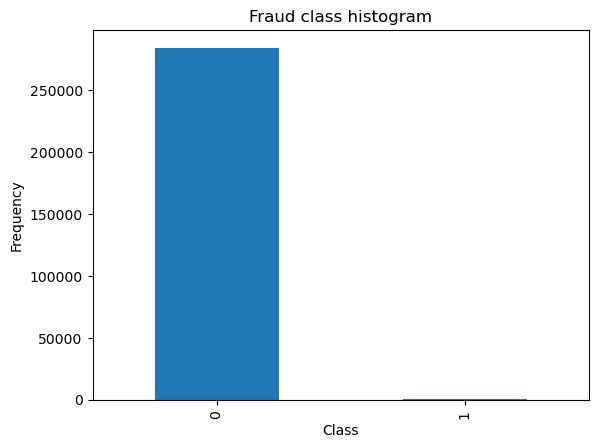

In [20]:
count_classes = data["Class"].value_counts().sort_index()

count_classes.plot(kind="bar")
plt.title("Fraud class histogram")
plt.xlabel("Class")
plt.ylabel("Frequency")
plt.show()

In [21]:
print("0:", (data['Class']==0).sum())
print("1:", (data['Class']==1).sum())

0: 284315
1: 492


**Result Explained** The histogram and above output tell us the dataset is highly unbalanced.

In [22]:
data['Amount']

0         149.62
1           2.69
2         378.66
3         123.50
4          69.99
           ...  
284802      0.77
284803     24.79
284804     67.88
284805     10.00
284806    217.00
Name: Amount, Length: 284807, dtype: float64

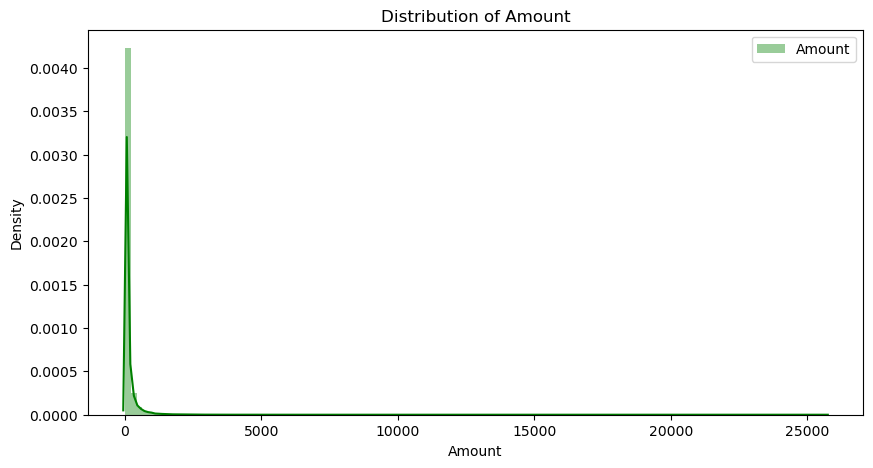

In [23]:
from sklearn.preprocessing import StandardScaler
import seaborn as sns


data['normAmount'] = StandardScaler().fit_transform(data['Amount'].values.reshape(-1, 1))

# Distribution of Amount
plt.figure(figsize=(10,5))
plt.title('Distribution of Amount')
sns.distplot(data['Amount'], color='green', kde=True, bins=120, label='Amount')
plt.legend()
plt.show()

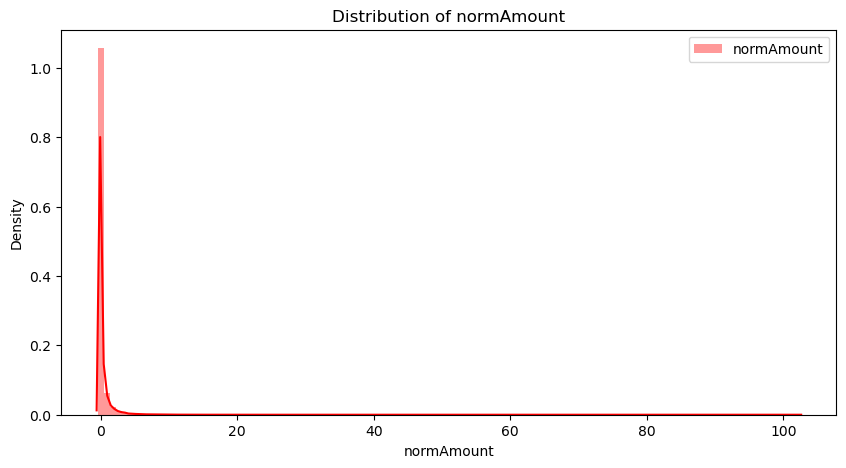

In [24]:
# Distribution of normAmount

plt.figure(figsize=(10,5))
plt.title('Distribution of normAmount')
sns.distplot(data['normAmount'], color='red', kde=True, bins=120, label='normAmount')
plt.legend()
plt.show()

In [25]:
data = data.drop(['Time','Amount'], axis=1)
data.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Class,normAmount
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0,0.244964
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0,-0.342475
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0,1.160686
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0,0.140534
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0,-0.073403


**Result Explained** 

**sklearn.preprocessing.StandardScaler**
Class sklearn.preprocessing.StandardScaler(*, copy=True, with_mean=True, with_std=True)
Standardize features by removing the mean and scaling to unit variance. 
The standard score of a sample x is calculated as:
z = (x - u) / s 
where u is the mean of the training samples or zero if with_mean=False, and s is the standard deviation of the training samples or one if with_std=False.

**fit_transform(X)** returns a transformed version of X

**'Amount'** column has a variance that is orders of magnitude larger than others, it might dominate the objective function and make the estimator unable to learn from other features correctly as expected.

https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html?highlight=standardscaler#sklearn.preprocessing.StandardScaler


In [26]:
data.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Class,normAmount
count,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,2.848070e+05
mean,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,2.239053e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,0.001727,2.913952e-17
std,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,0.041527,1.000002e+00
min,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,-3.532294e-01
25%,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,0.000000,-3.308401e-01
50%,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,0.000000,-2.652715e-01
75%,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,0.000000,-4.471707e-02
max,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,1.000000,1.023622e+02


**Undersampling** is a technique to balance uneven datasets by keeping all of the data in the minority class and decreasing the size of the majority class.

In [27]:
X = data.loc[:, data.columns != 'Class']
y = data.loc[:, data.columns == 'Class']

# Number of data points in the minority class
number_records_fraud = len(data[data.Class == 1])
fraud_indices = np.array(data[data.Class == 1].index)
print("number_records_fraud: ", number_records_fraud)

# Picking the indices of the normal classes
normal_indices = data[data.Class == 0].index

# Out of the indices we picked, randomly select "x" number 
#The number of normal records picked = number_records_fraud
random_normal_indices = np.random.choice(normal_indices, number_records_fraud, replace = False)
random_normal_indices = np.array(random_normal_indices)

# Appending the 2 indices
under_sample_indices = np.concatenate([fraud_indices,random_normal_indices])

# Under sample dataset
under_sample_data = data.iloc[under_sample_indices,:]

X_undersample = under_sample_data.loc[:, under_sample_data.columns != 'Class']
y_undersample = under_sample_data.loc[:, under_sample_data.columns == 'Class']

# Showing ratio
print("Percentage of normal transactions: ", len(under_sample_data[under_sample_data.Class == 0])/len(under_sample_data))
print("Percentage of fraud transactions: ", len(under_sample_data[under_sample_data.Class == 1])/len(under_sample_data))
print("Total number of transactions in resampled data: ", len(under_sample_data))

number_records_fraud:  492
Percentage of normal transactions:  0.5
Percentage of fraud transactions:  0.5
Total number of transactions in resampled data:  984


## 4 Modeling 
### Training and Testing
<img src="./imgs/modeling.png"  alt="ImageFile" style="width: 600px;" align="left"/>


### Train, Validation and Test
<img src="./imgs/dataset1.png"  alt="ImageFile" style="width: 600px;" align="left"/>
<img src="./imgs/dataset2.png"  alt="ImageFile" style="width: 600px;" align="left"/>


### K-fold Cross Validation
<img src="./imgs/k_fold.PNG"  alt="ImageFile" style="width: 600px;" align="left"/>

In [28]:
from sklearn.model_selection import train_test_split

# Whole dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 0)

print("Number transactions train dataset: ", len(X_train))
print("Number transactions test dataset: ", len(X_test))
print("Total number of transactions: ", len(X_train)+len(X_test))

# Undersampled dataset
X_train_undersample, X_test_undersample, y_train_undersample, y_test_undersample = train_test_split(X_undersample
                                                                                                   ,y_undersample
                                                                                                   ,test_size = 0.3
                                                                                                   ,random_state = 0)
print("")
print("Number transactions train dataset: ", len(X_train_undersample))
print("Number transactions test dataset: ", len(X_test_undersample))
print("Total number of transactions: ", len(X_train_undersample)+len(X_test_undersample))

Number transactions train dataset:  199364
Number transactions test dataset:  85443
Total number of transactions:  284807

Number transactions train dataset:  688
Number transactions test dataset:  296
Total number of transactions:  984


### Confusion matrix
<img src="./imgs/Confusion_matrix.png"  alt="ImageFile" style="width: 600px;" align="left"/>

### Evaluation metrics
<img src="./imgs/Evaluation_metrics.png"  alt="ImageFile" style="width: 600px;" align="left"/>

In [29]:
#Recall = TP/(TP+FN)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import confusion_matrix,recall_score,classification_report 

In [30]:
def printing_Kfold_scores(x_train_data, y_train_data):
    fold = KFold(5,shuffle=False) 

    # Different C parameters
    c_param_range = [0.01,0.1,1,10,100]

    results_table = pd.DataFrame(index = range(len(c_param_range),2), columns = ['C_parameter','Mean recall score'])
    results_table['C_parameter'] = c_param_range

    # the k-fold will give 2 lists: train_indices = indices[0], test_indices = indices[1]
    j = 0
    for c_param in c_param_range:
        print('-------------------------------------------')
        print('C parameter: ', c_param)
        print('-------------------------------------------')
        print('')

        recall_accs = []
        for iteration, indices in enumerate(fold.split(y_train_data), start=1):

            # Call the logistic regression model with a certain C parameter
            lr = LogisticRegression(C = c_param, penalty = 'l1', solver='liblinear')

            # Use the training data to fit the model. In this case, we use the portion of the fold to train the model
            # with indices[0]. We then predict on the portion assigned as the 'test cross validation' with indices[1]
            lr.fit(x_train_data.iloc[indices[0],:],y_train_data.iloc[indices[0],:].values.ravel())

            # Predict values using the test indices in the training data
            y_pred_undersample = lr.predict(x_train_data.iloc[indices[1],:].values)

            # Calculate the recall score and append it to a list for recall scores representing the current c_parameter
            recall_acc = recall_score(y_train_data.iloc[indices[1],:].values, y_pred_undersample)
            recall_accs.append(recall_acc)
            print('Iteration ', iteration,': recall score = ', recall_acc)

        # The mean value of those recall scores is the metric we want to save and get hold of.
        results_table.loc[j,'Mean recall score'] = np.mean(recall_accs)
        j += 1
        print('')
        print('Mean recall score ', np.mean(recall_accs))
        print('')


    best_c = results_table.loc[results_table['Mean recall score'].astype(float).idxmax()]['C_parameter']
    
    # Finally, we can check which C parameter is the best amongst the chosen.
    print('*********************************************************************************')
    print('Best model to choose from cross validation is with C parameter = ', best_c)
    print('*********************************************************************************')
    
    return best_c

In [31]:
best_c = printing_Kfold_scores(X_train_undersample, y_train_undersample)

-------------------------------------------
C parameter:  0.01
-------------------------------------------

Iteration  1 : recall score =  0.958904109589041
Iteration  2 : recall score =  0.9315068493150684
Iteration  3 : recall score =  1.0
Iteration  4 : recall score =  0.972972972972973
Iteration  5 : recall score =  0.9545454545454546

Mean recall score  0.9635858772845076

-------------------------------------------
C parameter:  0.1
-------------------------------------------

Iteration  1 : recall score =  0.8493150684931506
Iteration  2 : recall score =  0.863013698630137
Iteration  3 : recall score =  0.9322033898305084
Iteration  4 : recall score =  0.9324324324324325
Iteration  5 : recall score =  0.9090909090909091

Mean recall score  0.8972110996954274

-------------------------------------------
C parameter:  1
-------------------------------------------

Iteration  1 : recall score =  0.8493150684931506
Iteration  2 : recall score =  0.8904109589041096
Iteration  3 : rec

In [32]:
def plot_confusion_matrix(cm, classes,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=0)
    plt.yticks(tick_marks, classes)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

Recall metric in the testing dataset:  0.9387755102040817


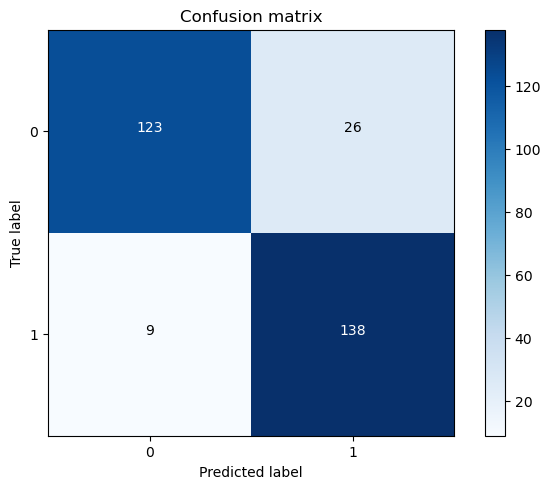

In [33]:
# X_test_undersample
import itertools
lr = LogisticRegression(C = best_c, penalty = 'l1', solver='liblinear')
lr.fit(X_train_undersample, y_train_undersample.values.ravel())
y_pred_undersample = lr.predict(X_test_undersample.values)

# Compute confusion matrix
cnf_matrix = confusion_matrix(y_test_undersample, y_pred_undersample)
np.set_printoptions(precision=2)

print("Recall metric in the testing dataset: ", cnf_matrix[1,1]/(cnf_matrix[1,0]+cnf_matrix[1,1]))

# Plot non-normalized confusion matrix
class_names = [0,1]
plt.figure()
plot_confusion_matrix(cnf_matrix
                      , classes=class_names
                      , title='Confusion matrix')
plt.show()

Recall metric in the testing dataset:  0.9251700680272109


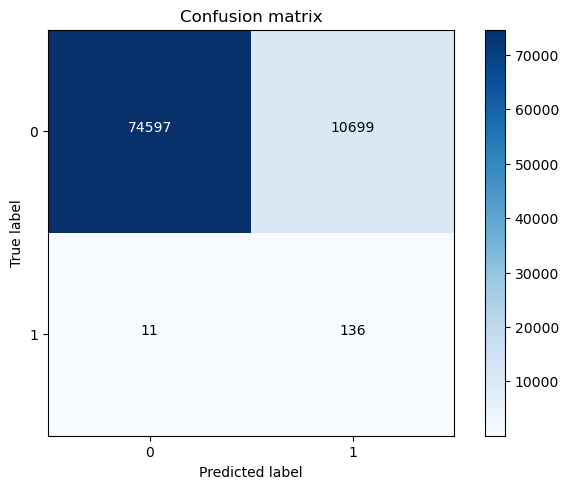

In [34]:
# X_test
lr = LogisticRegression(C = best_c, penalty = 'l1', solver='liblinear')
lr.fit(X_train_undersample, y_train_undersample.values.ravel())
y_pred = lr.predict(X_test.values)

# Compute confusion matrix
cnf_matrix = confusion_matrix(y_test, y_pred)
np.set_printoptions(precision=2)

print("Recall metric in the testing dataset: ", cnf_matrix[1,1]/(cnf_matrix[1,0]+cnf_matrix[1,1]))

# Plot non-normalized confusion matrix
class_names = [0,1]
plt.figure()
plot_confusion_matrix(cnf_matrix
                      , classes=class_names
                      , title='Confusion matrix')
plt.show()

In [35]:
best_c = printing_Kfold_scores(X_train,y_train)

-------------------------------------------
C parameter:  0.01
-------------------------------------------

Iteration  1 : recall score =  0.4925373134328358
Iteration  2 : recall score =  0.6027397260273972
Iteration  3 : recall score =  0.6833333333333333
Iteration  4 : recall score =  0.5692307692307692
Iteration  5 : recall score =  0.45

Mean recall score  0.5595682284048672

-------------------------------------------
C parameter:  0.1
-------------------------------------------

Iteration  1 : recall score =  0.5671641791044776
Iteration  2 : recall score =  0.6164383561643836
Iteration  3 : recall score =  0.6833333333333333
Iteration  4 : recall score =  0.5846153846153846
Iteration  5 : recall score =  0.525

Mean recall score  0.5953102506435158

-------------------------------------------
C parameter:  1
-------------------------------------------

Iteration  1 : recall score =  0.5522388059701493
Iteration  2 : recall score =  0.6164383561643836
Iteration  3 : recall score

Recall metric in the testing dataset:  0.6190476190476191


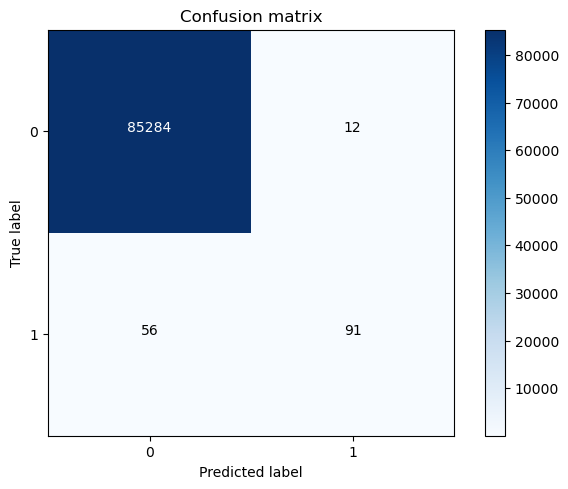

In [36]:
# X_test
lr = LogisticRegression(C = best_c, penalty = 'l1', solver='liblinear')
lr.fit(X_train,y_train.values.ravel())
y_pred_undersample = lr.predict(X_test.values)

# Compute confusion matrix
cnf_matrix = confusion_matrix(y_test,y_pred_undersample)
np.set_printoptions(precision=2)

print("Recall metric in the testing dataset: ", cnf_matrix[1,1]/(cnf_matrix[1,0]+cnf_matrix[1,1]))

# Plot non-normalized confusion matrix
class_names = [0,1]
plt.figure()
plot_confusion_matrix(cnf_matrix
                      , classes=class_names
                      , title='Confusion matrix')
plt.show()

## 5 Visualization

Recall metric in the testing dataset:  1.0
Recall metric in the testing dataset:  1.0
Recall metric in the testing dataset:  1.0
Recall metric in the testing dataset:  0.9863945578231292
Recall metric in the testing dataset:  0.9387755102040817
Recall metric in the testing dataset:  0.8979591836734694
Recall metric in the testing dataset:  0.8367346938775511
Recall metric in the testing dataset:  0.782312925170068
Recall metric in the testing dataset:  0.5918367346938775


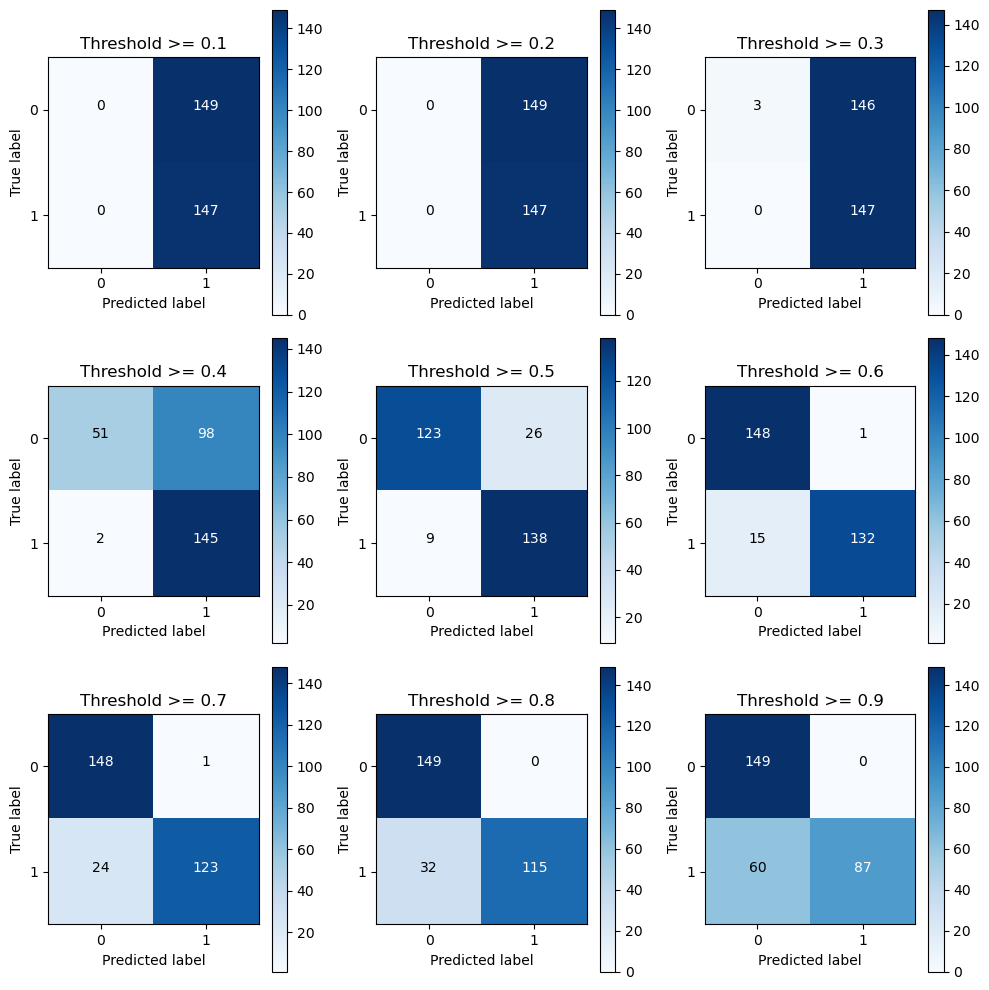

In [37]:
lr = LogisticRegression(C = 0.01, penalty = 'l1', solver='liblinear')
lr.fit(X_train_undersample,y_train_undersample.values.ravel())
y_pred_undersample_proba = lr.predict_proba(X_test_undersample.values)

thresholds = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9]

plt.figure(figsize=(10,10))

j = 1
for i in thresholds:
    y_test_predictions_high_recall = y_pred_undersample_proba[:,1] > i
    
    plt.subplot(3,3,j)
    j += 1
    
    # Compute confusion matrix
    cnf_matrix = confusion_matrix(y_test_undersample, y_test_predictions_high_recall)
    np.set_printoptions(precision=2)

    print("Recall metric in the testing dataset: ", cnf_matrix[1,1]/(cnf_matrix[1,0]+cnf_matrix[1,1]))

    # Plot non-normalized confusion matrix
    class_names = [0,1]
    plot_confusion_matrix(cnf_matrix
                          , classes=class_names
                          , title='Threshold >= %s'%i) 

# 6 Final Implementation: Undersampling + Tuned SVM vs Logistic Regression

下面这一节是本练习的最终实现。它会重新读取原始 `creditcard.csv`，因此不依赖前面旧单元格修改过的 `data` 变量。

**关键原则：**

1. 先划分训练集和测试集，再只对训练集进行随机欠采样；测试集保留真实的不平衡比例。
2. 用 `Pipeline` 把标准化和模型绑定，避免交叉验证时发生数据泄漏。
3. 用交叉验证搜索 SVM 的 `kernel`、`C` 和 `gamma`，并用 F1-score 选择最终模型。
4. 在同一测试集上比较 SVM 和 Logistic Regression 的 Precision、Recall、F1、PR-AUC、混淆矩阵、训练时间和预测时间。

> 后续代码是独立的最终实验入口，建议从下面第一个代码单元开始按顺序运行。

In [38]:
# ==================== 6.1 导入依赖并读取原始数据 ====================
# 这一单元重新读取原始文件，避免受到前面旧实验单元格的变量修改影响。
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, accuracy_score,
    average_precision_score, roc_auc_score, precision_recall_curve
)

RANDOM_STATE = 42
DATA_PATH = "creditcard.csv"

raw_data = pd.read_csv(DATA_PATH)
if "Class" not in raw_data.columns:
    raise ValueError("数据集必须包含名为 Class 的标签列。")

if raw_data.isna().any().any():
    raise ValueError("数据集中存在缺失值，请先处理缺失值后再训练模型。")

X = raw_data.drop(columns="Class")
y = raw_data["Class"].astype(int)

print("原始数据形状:", raw_data.shape)
print("原始类别分布:")
print(y.value_counts().sort_index())
print("\n原始欺诈比例: {:.4%}".format(y.mean()))

原始数据形状: (284807, 31)
原始类别分布:
Class
0    284315
1       492
Name: count, dtype: int64

原始欺诈比例: 0.1727%


In [39]:
# ==================== 6.2 划分数据并进行手动欠采样 ====================
# 必须先划分数据，再只对训练集欠采样。
# 如果对全数据欠采样，测试集会失去真实的类别比例，评估结果会偏乐观。
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)


def manual_undersample(X_input, y_input, random_state=42):
    """保留全部少数类，并随机抽取等量多数类样本。"""
    rng = np.random.default_rng(random_state)
    y_array = np.asarray(y_input)
    minority_label = 1
    majority_label = 0

    minority_indices = np.flatnonzero(y_array == minority_label)
    majority_indices = np.flatnonzero(y_array == majority_label)
    sample_size = min(len(minority_indices), len(majority_indices))

    selected_majority = rng.choice(
        majority_indices, size=sample_size, replace=False
    )
    selected_indices = np.concatenate([minority_indices, selected_majority])
    rng.shuffle(selected_indices)

    # iloc 使用位置索引，能正确处理原始 DataFrame 的任意索引标签。
    X_result = X_input.iloc[selected_indices].copy()
    y_result = y_input.iloc[selected_indices].copy()
    return X_result, y_result


X_train_under, y_train_under = manual_undersample(
    X_train, y_train, random_state=RANDOM_STATE
)

print("训练集欠采样前:")
print(y_train.value_counts().sort_index())
print("\n训练集欠采样后:")
print(y_train_under.value_counts().sort_index())
print("\n测试集保持原始不平衡比例:")
print(y_test.value_counts().sort_index())

assert y_train_under.value_counts().nunique() == 1
assert len(X_train_under) == len(y_train_under)

训练集欠采样前:
Class
0    227451
1       394
Name: count, dtype: int64

训练集欠采样后:
Class
0    394
1    394
Name: count, dtype: int64

测试集保持原始不平衡比例:
Class
0    56864
1       98
Name: count, dtype: int64


In [40]:
# ==================== 6.3 SVM 参数搜索 ====================
# StandardScaler 必须放在 Pipeline 中：每一个交叉验证训练折单独拟合 scaler，防止数据泄漏。
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(random_state=RANDOM_STATE))
])

# C 控制误分类惩罚；gamma 控制 RBF 核的影响范围。
# linear 用于比较线性边界，rbf 用于学习非线性边界。
svm_param_grid = [
    {"model__kernel": ["linear"], "model__C": [0.1, 1, 10]},
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.001, 0.01]
    }
]

svm_search = GridSearchCV(
    svm_pipeline,
    svm_param_grid,
    scoring={"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"},
    refit="f1",
    cv=5,
    n_jobs=-1,
    return_train_score=False
)

svm_search_start = time.perf_counter()
svm_search.fit(X_train_under, y_train_under)
svm_search_time = time.perf_counter() - svm_search_start

print("SVM 网格搜索耗时: {:.2f} 秒".format(svm_search_time))
print("SVM 最佳参数:", svm_search.best_params_)
print("SVM 最佳交叉验证 F1: {:.4f}".format(svm_search.best_score_))

svm_cv = pd.DataFrame(svm_search.cv_results_)
print("\nSVM 参数组合排名:")
display(svm_cv[["params", "mean_test_precision", "mean_test_recall", "mean_test_f1", "mean_test_roc_auc"]].sort_values("mean_test_f1", ascending=False).head(10))

SVM 网格搜索耗时: 2.40 秒
SVM 最佳参数: {'model__C': 10, 'model__kernel': 'linear'}
SVM 最佳交叉验证 F1: 0.9413

SVM 参数组合排名:


,params,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_roc_auc
2,"{'model__C': 10, 'model__kernel': 'linear'}",0.967946,0.916261,0.941304,0.974458
11,"{'model__C': 10, 'model__gamma': 0.01, 'model_...",0.981042,0.898539,0.937701,0.983176
1,"{'model__C': 1, 'model__kernel': 'linear'}",0.967673,0.908666,0.937183,0.975795
9,"{'model__C': 10, 'model__gamma': 'scale', 'mod...",0.955386,0.918825,0.936601,0.978038
6,"{'model__C': 1, 'model__gamma': 'scale', 'mode...",0.980776,0.896008,0.936294,0.980472
0,"{'model__C': 0.1, 'model__kernel': 'linear'}",0.983710,0.890912,0.934825,0.977566
8,"{'model__C': 1, 'model__gamma': 0.01, 'model__...",0.991346,0.857936,0.919685,0.981443
10,"{'model__C': 10, 'model__gamma': 0.001, 'model...",0.991219,0.855372,0.918236,0.979687
3,"{'model__C': 0.1, 'model__gamma': 'scale', 'mo...",0.982520,0.847777,0.910050,0.970677
5,"{'model__C': 0.1, 'model__gamma': 0.01, 'model...",0.996923,0.794482,0.884123,0.975093


In [41]:
# ==================== 6.4 LR 基准模型参数搜索 ====================
# LR 作为基准模型，同样使用相同的欠采样训练集和 Pipeline。
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "model",
        LogisticRegression(
            solver="liblinear",
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

lr_search = GridSearchCV(
    lr_pipeline,
    {"model__C": [0.01, 0.1, 1, 10], "model__penalty": ["l1", "l2"]},
    scoring={"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"},
    refit="f1",
    cv=5,
    n_jobs=-1,
    return_train_score=False
)

lr_search_start = time.perf_counter()
lr_search.fit(X_train_under, y_train_under)
lr_search_time = time.perf_counter() - lr_search_start

print("LR 网格搜索耗时: {:.2f} 秒".format(lr_search_time))
print("LR 最佳参数:", lr_search.best_params_)
print("LR 最佳交叉验证 F1: {:.4f}".format(lr_search.best_score_))

LR 网格搜索耗时: 0.21 秒
LR 最佳参数: {'model__C': 1, 'model__penalty': 'l2'}
LR 最佳交叉验证 F1: 0.9397


In [42]:
# ==================== 6.5 在真实比例测试集上评估 ====================
best_svm = svm_search.best_estimator_
best_lr = lr_search.best_estimator_

# 重新计时：只测量最佳模型的一次完整训练和测试预测。
def fit_and_measure(model, X_fit, y_fit, X_eval):
    fitted_model = clone(model)
    start = time.perf_counter()
    fitted_model.fit(X_fit, y_fit)
    train_seconds = time.perf_counter() - start

    start = time.perf_counter()
    predictions = fitted_model.predict(X_eval)
    predict_seconds = time.perf_counter() - start
    return fitted_model, predictions, train_seconds, predict_seconds

svm_model, svm_pred, svm_train_time, svm_predict_time = fit_and_measure(
    best_svm, X_train_under, y_train_under, X_test
)
lr_model, lr_pred, lr_train_time, lr_predict_time = fit_and_measure(
    best_lr, X_train_under, y_train_under, X_test
)

print("SVM 测试集分类报告:")
print(classification_report(y_test, svm_pred, target_names=["正常交易", "欺诈交易"], digits=4, zero_division=0))
print("LR 测试集分类报告:")
print(classification_report(y_test, lr_pred, target_names=["正常交易", "欺诈交易"], digits=4, zero_division=0))

# decision_function 的值越大，越倾向于判定为欺诈；它可用于计算 PR-AUC。
svm_score = svm_model.decision_function(X_test)
lr_score = lr_model.predict_proba(X_test)[:, 1]


def result_row(name, y_true, y_pred, score, train_seconds, predict_seconds):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, score),
        "PR-AUC": average_precision_score(y_true, score),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Train seconds": train_seconds,
        "Predict seconds": predict_seconds,
        "ms/sample": predict_seconds * 1000 / len(y_true)
    }

summary = pd.DataFrame([
    result_row("SVM", y_test, svm_pred, svm_score, svm_train_time, svm_predict_time),
    result_row("LR", y_test, lr_pred, lr_score, lr_train_time, lr_predict_time)
])

print("最终测试集比较（测试集保持真实不平衡比例）:")
display(summary.round(4))

SVM 测试集分类报告:
              precision    recall  f1-score   support

        正常交易     0.9999    0.9645    0.9818     56864
        欺诈交易     0.0427    0.9184    0.0815        98

    accuracy                         0.9644     56962
   macro avg     0.5213    0.9414    0.5317     56962
weighted avg     0.9982    0.9644    0.9803     56962

LR 测试集分类报告:
              precision    recall  f1-score   support

        正常交易     0.9998    0.9640    0.9816     56864
        欺诈交易     0.0416    0.9082    0.0796        98

    accuracy                         0.9639     56962
   macro avg     0.5207    0.9361    0.5306     56962
weighted avg     0.9982    0.9639    0.9800     56962

最终测试集比较（测试集保持真实不平衡比例）:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP,Train seconds,Predict seconds,ms/sample
0,SVM,0.9644,0.0427,0.9184,0.0815,0.9765,0.6340,54844,2020,8,90,0.015,0.0893,0.0016
1,LR,0.9639,0.0416,0.9082,0.0796,0.9690,0.2985,54815,2049,9,89,0.003,0.0055,0.0001


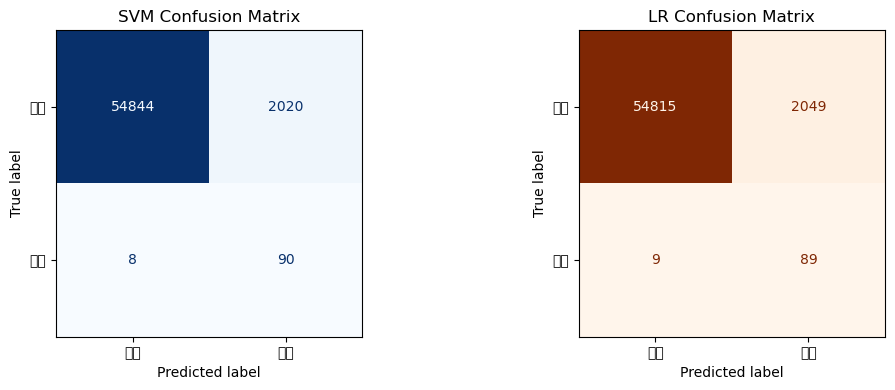

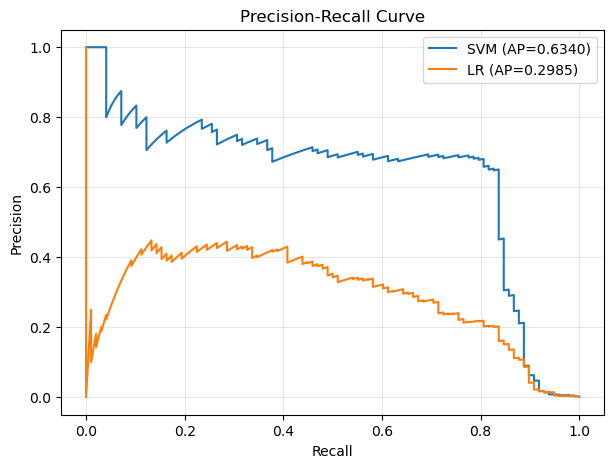

解释：欺诈检测通常重点关注 Recall 和 FN，因为 FN 表示真实欺诈却没有被检测出来。


In [43]:
# ==================== 6.6 混淆矩阵与 PR 曲线 ====================
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, svm_pred),
    display_labels=["正常", "欺诈"]
).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("SVM Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, lr_pred),
    display_labels=["正常", "欺诈"]
).plot(ax=axes[1], cmap="Oranges", values_format="d", colorbar=False)
axes[1].set_title("LR Confusion Matrix")
plt.tight_layout()
plt.show()

svm_precision, svm_recall, _ = precision_recall_curve(y_test, svm_score)
lr_precision, lr_recall, _ = precision_recall_curve(y_test, lr_score)

plt.figure(figsize=(7, 5))
plt.plot(svm_recall, svm_precision, label="SVM (AP={:.4f})".format(average_precision_score(y_test, svm_score)))
plt.plot(lr_recall, lr_precision, label="LR (AP={:.4f})".format(average_precision_score(y_test, lr_score)))
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("解释：欺诈检测通常重点关注 Recall 和 FN，因为 FN 表示真实欺诈却没有被检测出来。")